# 04 - Augmentation and Loading

Reusable reference preprocessing and on-demand saved-split loading. Only the training partition is augmented. Verify tensors, labels, ordering and seeded reproducibility without models, training, test images or changes to saved membership.

## 1. Project root, fixed inputs and datasets

Use the established root markers and project kernel. Snapshot the split, encoding, notebook 03 and dependencies before verification. Dataset construction reads metadata only, preserving manifest order.

In [1]:
from pathlib import Path
from datetime import datetime
import ast
import hashlib
import json
import math
import sys
import nbformat
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, RandomSampler, SequentialSampler

def find_project_root(start):
    start=Path(start).resolve()
    for candidate in (start,*start.parents):
        if (candidate/"requirements.txt").is_file() and (candidate/"notebooks/00_Environment_Check.ipynb").is_file():
            return candidate
    raise FileNotFoundError("Open the project root or notebooks directory.")

PROJECT_ROOT=find_project_root(Path.cwd())
assert find_project_root(PROJECT_ROOT/"notebooks")==PROJECT_ROOT
assert Path(sys.prefix).resolve()==PROJECT_ROOT/".venv"
assert Path(sys.executable).resolve().parent==PROJECT_ROOT/".venv/Scripts"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0,str(PROJECT_ROOT))
from src.data_pipeline import FacialFeatureDataset, reference_preprocess, resize_geometry, seed_everything
get_ipython().run_line_magic("matplotlib","inline")
SEED=42
BATCH_SIZE=32
checks={}

def require(name,condition):
    checks[name]=bool(condition)
    assert checks[name],name
    print(name+": PASS")

def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

protected=["data/processed/split_manifest.csv","data/processed/class_mapping.json",
           "notebooks/03_Split_and_Preprocessing.ipynb","requirements.txt","requirements-lock.txt"]
before_hashes={name:file_hash(PROJECT_ROOT/name) for name in protected}
manifest=pd.read_csv(PROJECT_ROOT/protected[0],dtype=str,keep_default_na=False,na_filter=False)
mapping=json.loads((PROJECT_ROOT/protected[1]).read_text(encoding="utf-8"))
previous=json.loads((PROJECT_ROOT/"outputs/metrics/split_preprocessing_check.json").read_text(encoding="utf-8"))
train_dataset=FacialFeatureDataset(PROJECT_ROOT,"train")
validation_dataset=FacialFeatureDataset(PROJECT_ROOT,"validation")
require("saved_dataset_lengths",len(train_dataset)==previous["rows"]["train"]==50927 and len(validation_dataset)==previous["rows"]["validation"]==12733)
for name,dataset in [("train",train_dataset),("validation",validation_dataset)]:
    expected=manifest.loc[manifest["split"].eq(name),["image_id","class","image_path"]].reset_index(drop=True)
    require(name+"_metadata_retains_saved_order",dataset.rows.equals(expected))
require("augmentation_is_training_only",train_dataset.augmentation is not None and validation_dataset.augmentation is None)
print("Train:",len(train_dataset),"Validation:",len(validation_dataset))


saved_dataset_lengths: PASS
train_metadata_retains_saved_order: PASS
validation_metadata_retains_saved_order: PASS
augmentation_is_training_only: PASS
Train: 50927 Validation: 12733


## 2. Exact equivalence to notebook 03

Extract only the three function definitions from notebook 03 with Python AST. Do not execute its split-writing or audit cells. Compare exact tensors and geometry on its saved representative training examples, including tiny and elongated images. Half-up rounding and odd padding on right/bottom remain unchanged.

In [2]:
notebook03=nbformat.read(PROJECT_ROOT/"notebooks/03_Split_and_Preprocessing.ipynb",as_version=4)
names={"resize_geometry","training_image_path","reference_preprocess"}
definitions=[]
for cell in notebook03.cells:
    if cell.cell_type=="code":
        definitions.extend(node for node in ast.parse(cell.source).body if isinstance(node,ast.FunctionDef) and node.name in names)
require("notebook03_reference_functions_found",{node.name for node in definitions}==names)
namespace={"PROJECT_ROOT":PROJECT_ROOT,"TRAIN_DIR":(PROJECT_ROOT/"data/raw/train/train").resolve(),
           "TARGET":224,"PAD_RGB":(128,128,128),"Image":Image,"torch":torch,"np":np}
exec(compile(ast.Module(body=definitions,type_ignores=[]),"notebook03_reference","exec"),namespace)
parity=[]
for item in previous["sample_checks"]:
    row=train_dataset.rows.loc[train_dataset.rows["image_id"].eq(item["image_id"])].iloc[0]
    old_tensor,old_geometry=namespace["reference_preprocess"](row["image_path"])
    with Image.open(PROJECT_ROOT/row["image_path"]) as image:
        image.load()
        new_tensor=reference_preprocess(image)
        new_geometry=resize_geometry(image.width,image.height)
    parity.append({"image_id":row["image_id"],"tensor_equal":torch.equal(old_tensor,new_tensor),"geometry_equal":old_geometry==new_geometry})
require("exact_preprocessing_equivalence",all(item["tensor_equal"] and item["geometry_equal"] for item in parity))
for width,height in [(224,223),(223,224),(448,3),(1,10000)]:
    require(f"geometry_equivalence_{width}x{height}",resize_geometry(width,height)==namespace["resize_geometry"](width,height))
print("Representative comparisons:",len(parity))


notebook03_reference_functions_found: PASS


exact_preprocessing_equivalence: PASS
geometry_equivalence_224x223: PASS
geometry_equivalence_223x224: PASS
geometry_equivalence_448x3: PASS
geometry_equivalence_1x10000: PASS
Representative comparisons: 12


## 3. Seeded loaders and batch checks

Seed Python, NumPy and torch with 42. Training uses its own seeded torch generator and shuffles; validation is sequential. Both loaders use batch size 32, zero workers and `drop_last=False`. Rebuilding with the same seeds reproduces the initial training batch. This does not mean augmentation should stay identical between epochs: normal iteration advances random state. No weighting, resampling or decoded dataset cache is used.

In [3]:
seed_everything(SEED)
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
                        generator=torch.Generator().manual_seed(SEED),num_workers=0,drop_last=False)
first_train=next(iter(train_loader))
# Reset both global augmentation RNGs and the loader's shuffle generator.
seed_everything(SEED)
rebuilt_train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
                                generator=torch.Generator().manual_seed(SEED),num_workers=0,drop_last=False)
rebuilt_first=next(iter(rebuilt_train_loader))
require("same_seeds_reproduce_initial_training_batch",torch.equal(first_train[0],rebuilt_first[0]) and torch.equal(first_train[1],rebuilt_first[1]) and list(first_train[2])==list(rebuilt_first[2]))
validation_loader=DataLoader(validation_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=0,drop_last=False)
first_validation=next(iter(validation_loader))
require("training_random_validation_sequential",isinstance(train_loader.sampler,RandomSampler) and isinstance(validation_loader.sampler,SequentialSampler))
require("loader_configuration",all(loader.batch_size==32 and loader.num_workers==0 and not loader.drop_last for loader in [train_loader,validation_loader]))
require("loader_batch_counts_include_partial_tails",len(train_loader)==math.ceil(len(train_dataset)/32) and len(validation_loader)==math.ceil(len(validation_dataset)/32))
require("validation_sampler_covers_manifest_order",list(validation_loader.sampler)==list(range(len(validation_dataset))))
require("validation_initial_batch_order",list(first_validation[2])==validation_dataset.rows["image_id"].head(32).tolist())
require("training_initial_batch_is_shuffled",list(first_train[2])!=train_dataset.rows["image_id"].head(32).tolist())
expected_labels=manifest.set_index("image_id")["class"].map(mapping["class_to_index"]).to_dict()
batch_results={}
for name,(images,labels,ids) in [("train",first_train),("validation",first_validation)]:
    outcomes={
        "shape":list(images.shape)==[len(ids),3,224,224] and len(ids)==32,
        "float32":images.dtype==torch.float32,"finite":bool(torch.isfinite(images).all()),
        "range_0_to_1":float(images.min())>=0 and float(images.max())<=1,
        "labels_int64":labels.dtype==torch.int64,"labels_in_0_to_7":bool(((labels>=0)&(labels<=7)).all()),
        "labels_match_original_ids":labels.tolist()==[expected_labels[image_id] for image_id in ids],
        "ids_remain_strings":all(isinstance(image_id,str) and len(image_id)==5 for image_id in ids),
    }
    require(name+"_batch_checks",all(outcomes.values()))
    batch_results[name]={"shape":list(images.shape),"dtype":str(images.dtype),"label_dtype":str(labels.dtype),
                         "minimum":float(images.min()),"maximum":float(images.max()),"ids":list(ids),"checks":outcomes}
validation_indices=sorted({0,1,len(validation_dataset)//2,len(validation_dataset)-1})
validation_repeats=[]
for index in validation_indices:
    first=validation_dataset[index]
    second=validation_dataset[index]
    with Image.open(PROJECT_ROOT/validation_dataset.rows.iloc[index]["image_path"]) as original:
        original.load()
        expected=reference_preprocess(original)
    validation_repeats.append(torch.equal(first[0],second[0]) and torch.equal(first[0],expected)
                              and first[1:]==second[1:] and first[2]==validation_dataset.rows.iloc[index]["image_id"])
require("validation_repeated_samples_identical_unaugmented",all(validation_repeats))
print("Observed batches:",{name:item["shape"] for name,item in batch_results.items()})


same_seeds_reproduce_initial_training_batch: PASS
training_random_validation_sequential: PASS
loader_configuration: PASS
loader_batch_counts_include_partial_tails: PASS
validation_sampler_covers_manifest_order: PASS
validation_initial_batch_order: PASS
training_initial_batch_is_shuffled: PASS
train_batch_checks: PASS
validation_batch_checks: PASS


validation_repeated_samples_identical_unaugmented: PASS
Observed batches: {'train': [32, 3, 224, 224], 'validation': [32, 3, 224, 224]}


## 4. Training-only stochastic augmentation preview

For the first saved training ID in each class, show the original RGB image and three independent augmented outputs. Resetting all seeds to 42 replays that sequence exactly; subsequent draws without resetting vary. Horizontal flip (p=0.5) and brightness/contrast jitter (0.1 each) occur before deterministic resizing/padding. No crop, rotation, vertical flip or label change is applied. Verify that padding stays exactly 128/255.

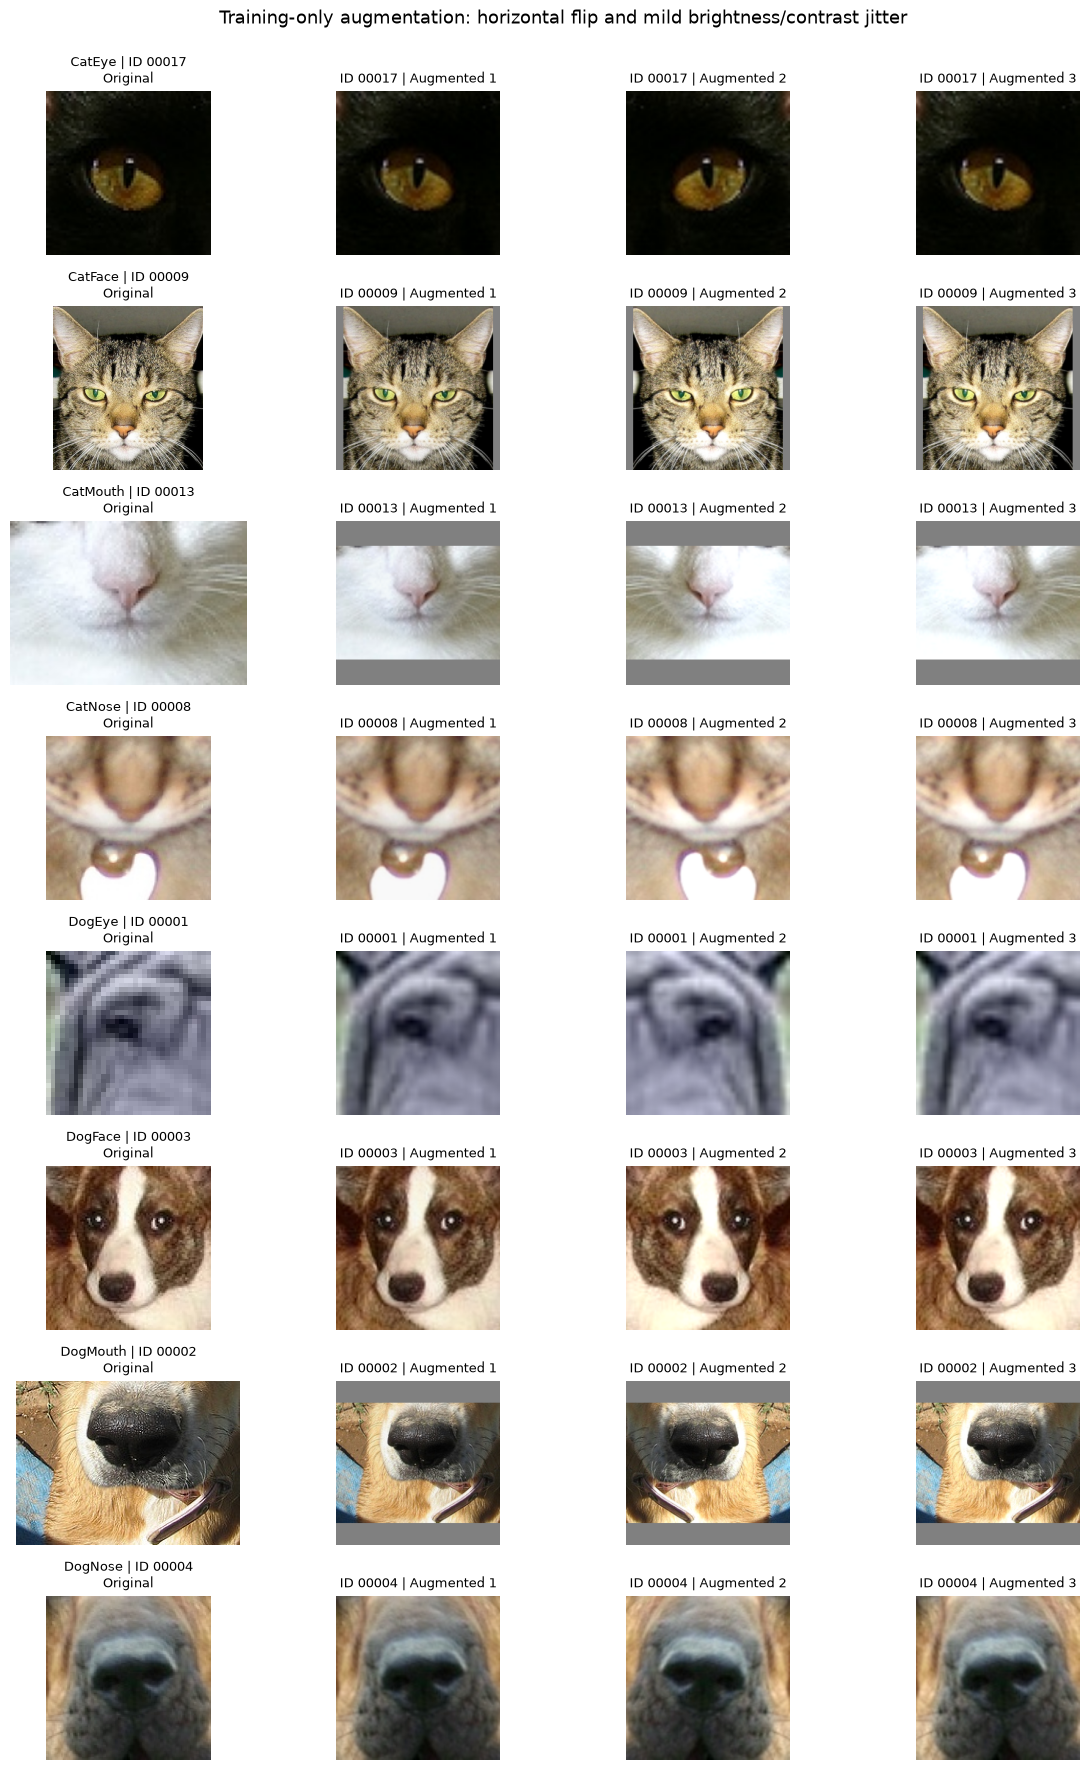

augmentation_examples_cover_all_eight_training_classes: PASS
selected_training_examples_show_stochastic_variation: PASS
seed_reset_reproduces_augmentation_sequences: PASS
augmentation_preserves_labels_and_fixed_padding: PASS
[
  {
    "image_id": "00017",
    "class": "CatEye",
    "distinct_outputs": 3,
    "seed_reset_reproduces_sequence": true,
    "labels_unchanged": true,
    "fixed_grey_padding": true
  },
  {
    "image_id": "00009",
    "class": "CatFace",
    "distinct_outputs": 3,
    "seed_reset_reproduces_sequence": true,
    "labels_unchanged": true,
    "fixed_grey_padding": true
  },
  {
    "image_id": "00013",
    "class": "CatMouth",
    "distinct_outputs": 3,
    "seed_reset_reproduces_sequence": true,
    "labels_unchanged": true,
    "fixed_grey_padding": true
  },
  {
    "image_id": "00008",
    "class": "CatNose",
    "distinct_outputs": 3,
    "seed_reset_reproduces_sequence": true,
    "labels_unchanged": true,
    "fixed_grey_padding": true
  },
  {
    "imag

In [4]:
classes=sorted(mapping["class_to_index"])
example_indices=[train_dataset.rows.index[train_dataset.rows["class"].eq(label)][0] for label in classes]
plt.rcParams.update({"font.size":9,"savefig.dpi":150})
fig,axes=plt.subplots(8,4,figsize=(12,18),squeeze=False)
augmentation_results=[]
fill=torch.tensor(128,dtype=torch.float32)/255
for panel_row,index in enumerate(example_indices):
    row=train_dataset.rows.iloc[index]
    seed_everything(SEED)
    sequence=[train_dataset[index] for _ in range(3)]
    seed_everything(SEED)
    replay=[train_dataset[index] for _ in range(3)]
    replay_equal=all(torch.equal(a[0],b[0]) and a[1:]==b[1:] for a,b in zip(sequence,replay))
    distinct=len({hashlib.sha256(item[0].numpy().tobytes()).hexdigest() for item in sequence})
    labels_ok=all(item[1]==mapping["class_to_index"][row["class"]] and item[2]==row["image_id"] for item in sequence)
    with Image.open(PROJECT_ROOT/row["image_path"]) as original:
        original.load()
        geometry=resize_geometry(original.width,original.height)
        with original.convert("RGB") as rgb:
            axes[panel_row,0].imshow(np.asarray(rgb),aspect="equal")
    axes[panel_row,0].set_title(f"{row['class']} | ID {row['image_id']}\nOriginal",fontsize=9)
    padding_ok=True
    for column,(tensor,label,image_id) in enumerate(sequence,start=1):
        for region in [tensor[:,:geometry["top"],:],tensor[:,224-geometry["bottom"]:,:],
                       tensor[:,:,:geometry["left"]],tensor[:,:,224-geometry["right"]:]]:
            padding_ok &= bool(torch.all(region==fill))
        axes[panel_row,column].imshow(tensor.permute(1,2,0).numpy(),aspect="equal")
        axes[panel_row,column].set_title(f"ID {image_id} | Augmented {column}",fontsize=9)
    for axis in axes[panel_row]: axis.axis("off")
    augmentation_results.append({"image_id":row["image_id"],"class":row["class"],"distinct_outputs":distinct,
                                 "seed_reset_reproduces_sequence":replay_equal,"labels_unchanged":labels_ok,"fixed_grey_padding":padding_ok})
fig.suptitle("Training-only augmentation: horizontal flip and mild brightness/contrast jitter",fontsize=13)
fig.tight_layout(rect=(0,0,1,0.98))
PREVIEW_PATH=PROJECT_ROOT/"outputs/figures/training_augmentation_preview.png"
fig.savefig(PREVIEW_PATH)
plt.show()
plt.close(fig)
require("augmentation_examples_cover_all_eight_training_classes",{item["class"] for item in augmentation_results}==set(classes))
require("selected_training_examples_show_stochastic_variation",all(item["distinct_outputs"]>1 for item in augmentation_results))
require("seed_reset_reproduces_augmentation_sequences",all(item["seed_reset_reproduces_sequence"] for item in augmentation_results))
require("augmentation_preserves_labels_and_fixed_padding",all(item["labels_unchanged"] and item["fixed_grey_padding"] for item in augmentation_results))
print(json.dumps(augmentation_results,indent=2))


## 5. Save loading evidence and verify protected files

Keep the fixed split, class mapping, previous notebook and dependency files unchanged. Only small batches and selected examples were decoded. No full dataset scan, model or training was performed.

In [5]:
after_hashes={name:file_hash(PROJECT_ROOT/name) for name in protected}
require("split_mapping_notebook03_and_dependencies_unchanged",before_hashes==after_hashes)
require("augmentation_preview_saved",PREVIEW_PATH.is_file() and PREVIEW_PATH.stat().st_size>0)
summary={
    "checked_at":datetime.now().astimezone().isoformat(),
    "configuration":{
        "seed":SEED,"seeded_libraries":["random","numpy","torch"],
        "batch_size":32,"num_workers":0,"drop_last":False,
        "training_shuffle":True,"training_generator_seed":SEED,"validation_shuffle":False,
        "augmentation_order":["RGB","RandomHorizontalFlip(p=0.5)","ColorJitter(brightness=0.1, contrast=0.1)","reference_preprocess"],
        "validation":"reference_preprocess only", "resize_rounding":"notebook03 exact half-up integer formula",
        "padding_rgb":[128,128,128],"padding":"odd extra pixel right/bottom; after augmentation",
        "tensor":"float32 CHW [3,224,224], /255 once; no pretrained normalisation",
        "class_weighting":False,"resampling":False,"decoded_dataset_cache":False,
    },
    "dataset_lengths":{"train":len(train_dataset),"validation":len(validation_dataset)},
    "loader_batch_counts":{"train":len(train_loader),"validation":len(validation_loader)},
    "final_batch_sizes_from_counts":{"train":len(train_dataset)%32 or 32,"validation":len(validation_dataset)%32 or 32},
    "observed_batches":batch_results,"preprocessing_parity":parity,
    "validation_repeated_indices":validation_indices,"augmentation_examples":augmentation_results,
    "protected_file_hashes_before":before_hashes,"protected_file_hashes_after":after_hashes,
    "checks":checks,"failed_checks":[name for name,passed in checks.items() if not passed],
    "limitations":["Identical seeds reproduce a restarted sequence, not identical augmentation every epoch.",
                   "Exact-content grouping does not establish independence of unidentified related crops or source animals.",
                   "Tiny images remain low-detail after resizing; no image or label was removed or corrected."],
    "execution":{"python_executable":sys.executable,"kernel_name":"enge707-assessment3","working_directory":str(Path.cwd())},
}
EVIDENCE_PATH=PROJECT_ROOT/"outputs/metrics/data_loading_check.json"
EVIDENCE_PATH.write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8")
assert json.loads(EVIDENCE_PATH.read_text(encoding="utf-8"))["checks"]==checks
print("Saved:",EVIDENCE_PATH.relative_to(PROJECT_ROOT))
print("All loading and augmentation checks passed.")


split_mapping_notebook03_and_dependencies_unchanged: PASS
augmentation_preview_saved: PASS
Saved: outputs\metrics\data_loading_check.json
All loading and augmentation checks passed.
